# KPI analysis

Charts of the five KPI views in the gold layer (`pf_gold.vw_...`). Every chart reads a view with one Athena query and shows
the numbers it is built from in a small table below it.

| Chart | View | The question |
|---|---|---|
| 1 | `vw_daily_admissions_discharges` | How many hospital stays start and end, per decade? |
| 2 | `vw_avg_los_by_facility_month` | How long do patients stay, per facility? |
| 3 | `vw_readmission_30d` | How many stays are readmissions within 30 days? |
| 4 | `vw_ed_volume_by_hour_dow` | When do emergency visits happen? |
| 5 | `vw_top_reasons` | Why do patients come? |

The data is synthetic (Synthea) and covers 1924-2026, with only 4 batches loaded, so the counts are small and the charts show how the pipeline's
output looks, not real hospital performance. All times are UTC.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

# Works whether Jupyter starts in the project root or in notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "infra"))

from aws_helpers import SETTINGS, run_athena, whoami

GOLD = SETTINGS["glue_databases"]["gold"]

# One palette, light surface. Series 1 blue, series 2 orange (checked: colour-blind safe, clearly distinct).
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUE, ORANGE = "#2a78d6", "#eb6834"
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]    # one hue, light to dark

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})


def query(sql):
    # Athena returns text; turn numeric columns into numbers
    result = run_athena(sql, timeout=300)
    frame = pd.DataFrame(result["rows"], columns=result["header"])
    for column in frame.columns:
        try:
            frame[column] = pd.to_numeric(frame[column])
        except (ValueError, TypeError):
            pass
    return frame


print("identity:", whoami())

identity: user/Ahmed


## 2. Hospital stays: admissions and discharges per decade
Counts per decade, because yearly counts are only 0-3 stays. Two series, so a legend and direct value labels. Decades without any stay are not shown.

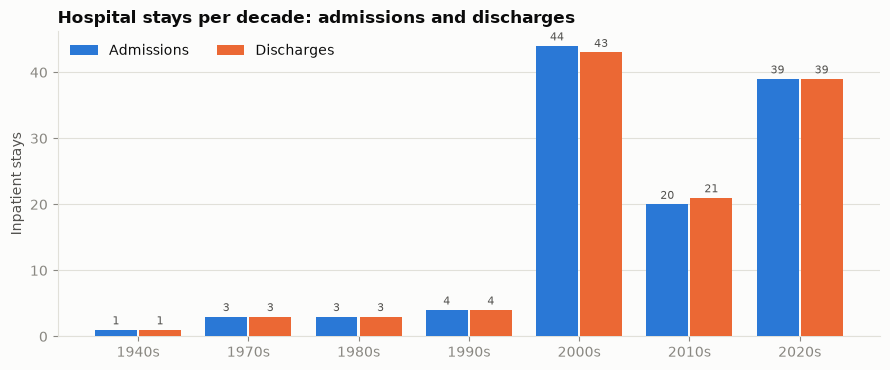

decade,1940,1970,1980,1990,2000,2010,2020
admissions,1,3,3,4,44,20,39
discharges,1,3,3,4,43,21,39


In [2]:
stays = query(f'''
    SELECT (year(date_key) / 10) * 10 AS decade, SUM(admissions) AS admissions, SUM(discharges) AS discharges
    FROM {GOLD}.vw_daily_admissions_discharges
    GROUP BY 1 ORDER BY 1''')

x = np.arange(len(stays))
width = 0.38
fig, ax = plt.subplots(figsize=(9, 3.8))
bars_a = ax.bar(x - width / 2 - 0.01, stays["admissions"], width, color=BLUE, label="Admissions", zorder=3)
bars_d = ax.bar(x + width / 2 + 0.01, stays["discharges"], width, color=ORANGE, label="Discharges", zorder=3)
for bars in (bars_a, bars_d):
    ax.bar_label(bars, fontsize=8, color=INK_2, padding=2)
ax.set_xticks(x, [f"{d}s" for d in stays["decade"]])
ax.set_ylabel("Inpatient stays")
ax.set_title("Hospital stays per decade: admissions and discharges")
ax.legend(loc="upper left", ncols=2)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
stays.set_index("decade").T

## 3. Length of stay by facility
Average days per inpatient stay for the facilities with the most stays (all months together, at least 2 stays: an average of one stay says nothing). One series, one colour; the number of stays is in the label.

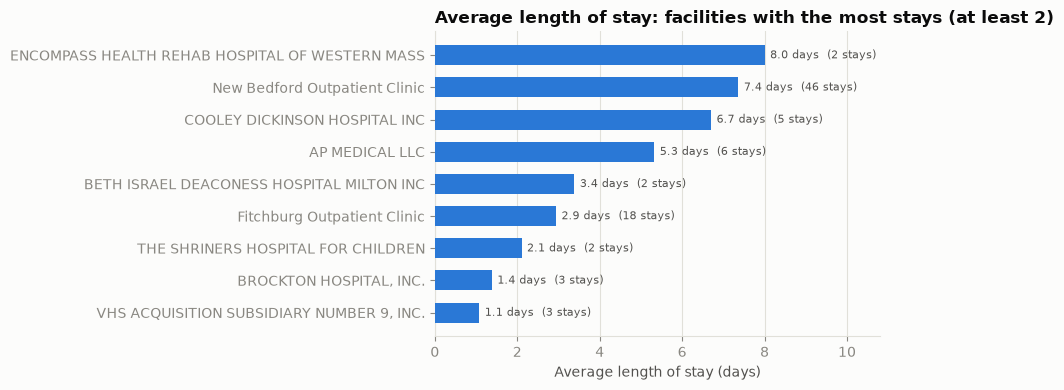

,facility_name,stays,avg_los_days
0,New Bedford Outpatient Clinic,46,7.36
1,Fitchburg Outpatient Clinic,18,2.94
2,AP MEDICAL LLC,6,5.32
3,COOLEY DICKINSON HOSPITAL INC,5,6.70
4,"VHS ACQUISITION SUBSIDIARY NUMBER 9, INC.",3,1.08
5,"BROCKTON HOSPITAL, INC.",3,1.38
6,THE SHRINERS HOSPITAL FOR CHILDREN,2,2.10
7,BETH ISRAEL DEACONESS HOSPITAL MILTON INC,2,3.38
8,ENCOMPASS HEALTH REHAB HOSPITAL OF WESTERN MASS,2,8.00


In [3]:
los = query(f'''
    SELECT facility_name, SUM(inpatient_stays) AS stays,
           SUM(avg_los_days * inpatient_stays) / SUM(inpatient_stays) AS avg_los_days
    FROM {GOLD}.vw_avg_los_by_facility_month
    GROUP BY facility_name HAVING SUM(inpatient_stays) >= 2 ORDER BY stays DESC, facility_name LIMIT 10''')
los = los.sort_values("avg_los_days")

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(los["facility_name"], los["avg_los_days"], color=BLUE, height=0.62, zorder=3)
ax.bar_label(bars, labels=[f"{d:.1f} days  ({n} stays)" for d, n in zip(los["avg_los_days"], los["stays"], strict=True)],
             fontsize=8, color=INK_2, padding=4)
ax.set_xlim(0, los["avg_los_days"].max() * 1.35)
ax.set_xlabel("Average length of stay (days)")
ax.set_title("Average length of stay: facilities with the most stays (at least 2)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
los[["facility_name", "stays", "avg_los_days"]].sort_values("stays", ascending=False).round(2).reset_index(drop=True)

## 4. 30-day readmissions per decade
A stay is a readmission if it starts within 30 days after the same patient's previous stay ended. Bars show the **share** of stays that are readmissions; the label gives the counts behind it,
because with few stays a high percentage can be one or two patients.

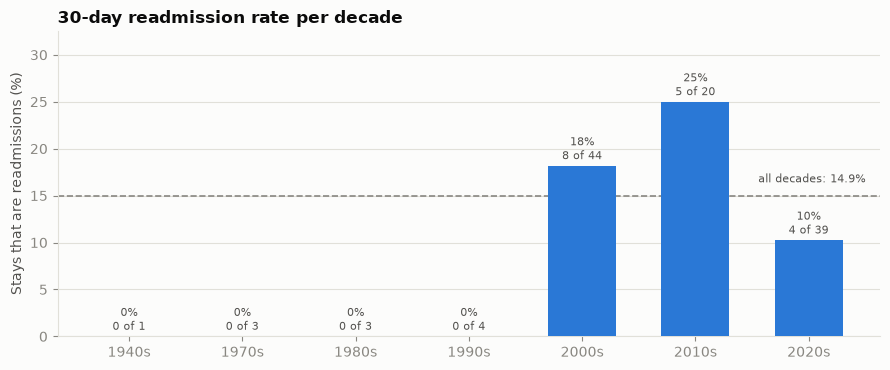

decade,1940,1970,1980,1990,2000,2010,2020
admissions,1.0,3.0,3.0,4.0,44.000,20.00,39.000
readmissions,0.0,0.0,0.0,0.0,8.000,5.00,4.000
rate,0.0,0.0,0.0,0.0,0.182,0.25,0.103


In [4]:
readmissions = query(f'''
    SELECT (year(month) / 10) * 10 AS decade, SUM(inpatient_admissions) AS admissions, SUM(readmissions_30d) AS readmissions
    FROM {GOLD}.vw_readmission_30d GROUP BY 1 ORDER BY 1''')
readmissions["rate"] = readmissions["readmissions"] / readmissions["admissions"]
overall = readmissions["readmissions"].sum() / readmissions["admissions"].sum()

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(readmissions))
bars = ax.bar(x, readmissions["rate"] * 100, 0.6, color=BLUE, zorder=3)
ax.bar_label(bars, labels=[f"{r:.0%}\n{k} of {n}" for r, k, n in
                           zip(readmissions["rate"], readmissions["readmissions"], readmissions["admissions"], strict=True)],
             fontsize=8, color=INK_2, padding=2)
ax.axhline(overall * 100, color=MUTED, linewidth=1.2, linestyle="--", zorder=2)
ax.text(len(x) - 0.5, overall * 100 + 1.5, f"all decades: {overall:.1%}", ha="right", fontsize=8, color=INK_2)
ax.set_xticks(x, [f"{d}s" for d in readmissions["decade"]])
ax.set_ylim(0, max(readmissions["rate"] * 100) * 1.3)
ax.set_ylabel("Stays that are readmissions (%)")
ax.set_title("30-day readmission rate per decade")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
readmissions.round(3).set_index("decade").T

## 5. Emergency visits by hour and weekday
Counts of emergency visits for each hour of the day (UTC) and weekday. One colour, light to dark: darker means more visits. Empty cells (no visits) are gray, so they are not mistaken for the lightest blue.

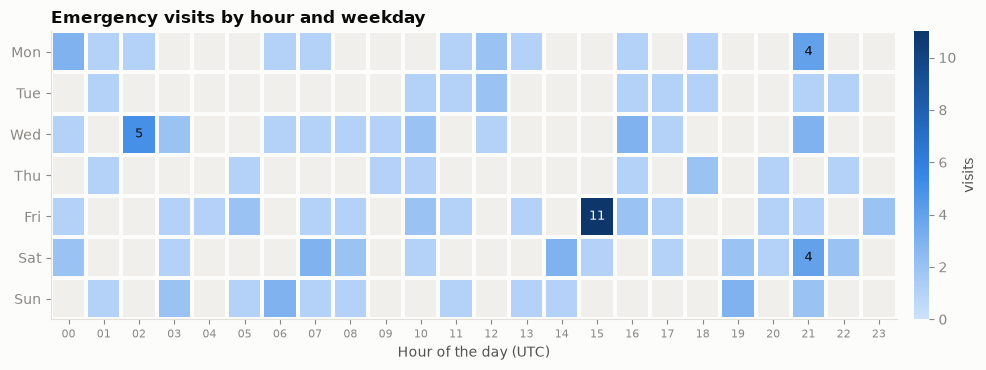

,hour_of_day_utc,day_of_week,emergency_visits
0,15,5,11
1,2,3,5
2,21,1,4
3,21,6,4
4,7,6,3


In [5]:
emergency = query(f"SELECT hour_of_day_utc, day_of_week, emergency_visits FROM {GOLD}.vw_ed_volume_by_hour_dow")
grid = np.zeros((7, 24))
for hour, weekday, visits in emergency.itertuples(index=False):
    grid[weekday - 1, hour] = visits

cmap = LinearSegmentedColormap.from_list("blue", BLUE_RAMP)
masked = np.ma.masked_where(grid == 0, grid)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.set_facecolor("#f0efec")                                    # colour of the masked (zero) cells
image = ax.pcolormesh(masked, cmap=cmap, edgecolors=SURFACE, linewidth=1.5, vmin=0, vmax=grid.max())
ax.set_xticks(np.arange(24) + 0.5, [f"{h:02d}" for h in range(24)], fontsize=8)
ax.set_yticks(np.arange(7) + 0.5, ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.invert_yaxis()
ax.grid(False)
ax.set_xlabel("Hour of the day (UTC)")
ax.set_title("Emergency visits by hour and weekday")
for weekday, hour in zip(*np.where(grid >= np.sort(grid.ravel())[-3]), strict=True):          # label the three busiest cells
    ax.text(hour + 0.5, weekday + 0.5, int(grid[weekday, hour]), ha="center", va="center", fontsize=9,
            color="white" if grid[weekday, hour] > grid.max() * 0.5 else INK)
colorbar = fig.colorbar(image, ax=ax, pad=0.02, fraction=0.03)
colorbar.set_label("visits", color=INK_2)
colorbar.outline.set_visible(False)
plt.tight_layout()
plt.show()
emergency.sort_values("emergency_visits", ascending=False).head(5).reset_index(drop=True)

## 6. Top reasons for visits
The ten reasons recorded on the most encounters. A few chronic patients account for a lot of the volume, so the table also shows how many different patients are behind each reason.

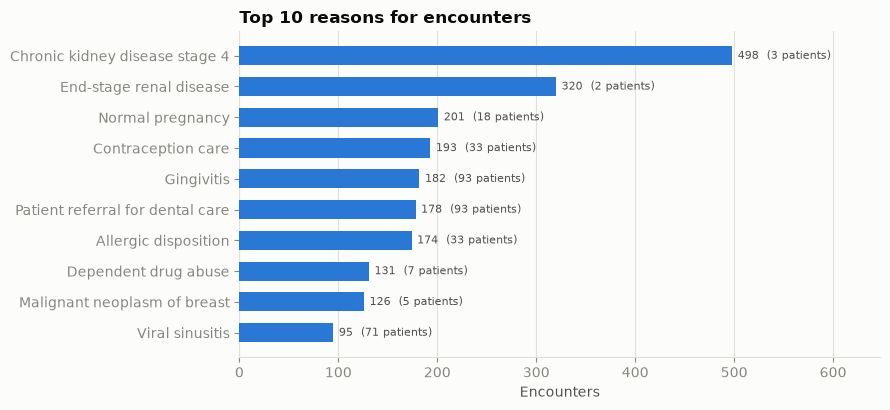

,reason_display,encounters,patients
0,Chronic kidney disease stage 4 (disorder),498,3
1,End-stage renal disease (disorder),320,2
2,Normal pregnancy (finding),201,18
3,Contraception care (regime/therapy),193,33
4,Gingivitis (disorder),182,93
5,Patient referral for dental care (procedure),178,93
6,Allergic disposition (finding),174,33
7,Dependent drug abuse (disorder),131,7
8,Malignant neoplasm of breast (disorder),126,5
9,Viral sinusitis (disorder),95,71


In [6]:
reasons = query(f'''
    SELECT reason_display, encounters, patients FROM {GOLD}.vw_top_reasons
    ORDER BY rank_by_volume, reason_display LIMIT 10''')
plot = reasons.sort_values("encounters")

fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.barh(plot["reason_display"].str.replace(r" \((.*)\)$", "", regex=True), plot["encounters"],
               color=BLUE, height=0.62, zorder=3)
ax.bar_label(bars, labels=[f"{e}  ({p} patients)" for e, p in zip(plot["encounters"], plot["patients"], strict=True)],
             fontsize=8, color=INK_2, padding=4)
ax.set_xlim(0, plot["encounters"].max() * 1.3)
ax.set_xlabel("Encounters")
ax.set_title("Top 10 reasons for encounters")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
reasons

## What to do with these charts
They are produced from the five gold views, so they refresh whenever the pipeline loads new batches: run this notebook again.
The same views are what a BI tool such as Power BI would connect to.